# 07 — Analisis Grad-CAM

Grad-CAM menyoroti wilayah citra yang paling memengaruhi keputusan model. Yang dicari di sini:

1. Untuk tiap kelas, bagian biji mana yang jadi dasar penilaian?
2. Apakah ketiga arsitektur memperhatikan area yang sama?
3. Pada prediksi yang salah, model sedang melihat apa?

**Catatan teknis.** Seluruh backbone dibekukan (`requires_grad=False`) karena skemanya feature extraction, sehingga graf autograd tidak terbentuk dan Grad-CAM akan gagal. `src.analysis.gradcam` menanganinya dengan menyalakan `requires_grad` **sementara** selama perhitungan CAM lalu mengembalikannya. Bobot model tidak pernah berubah.

> Heatmap ResNet-50/MobileNetV3 beresolusi 224, InceptionV3 299. Perbedaan ketajaman antar-kolom itu wajar dan memang bagian dari perbedaan arsitektur.

## Setup

In [1]:
# Bootstrap: tambahkan root proyek ke sys.path agar modul src/ & configs/ dapat diimpor.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('PROJECT_ROOT:', PROJECT_ROOT)

PROJECT_ROOT: C:\Users\DZXP\Documents\ta-green-bean


In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from configs.base_config import CLASS_NAMES, CROPS_DIR, DEVICE, FIGURES_DIR, MODELS_DIR, NUM_CLASSES, RANDOM_SEED
from configs.cnn_config import CNN_CONFIG, TARGET_LAYERS
from src.analysis.gradcam import (
    GradCAMAnalyzer,
    compare_architectures,
    select_correct_samples,
    select_sample_images,
)
from src.analysis.style import apply_plot_style
from src.evaluation.predict import load_predictions
from src.models.model_factory import get_model
from src.utils.io import load_checkpoint
from src.utils.seed import set_seed

apply_plot_style()
set_seed(RANDOM_SEED)
pd.Series(TARGET_LAYERS, name='target layer Grad-CAM').to_frame()

,target layer Grad-CAM
resnet50,layer4.-1
mobilenetv3,features.-1
inceptionv3,Mixed_7c


## 1. Muat model terlatih

In [3]:
def find_checkpoint(model_name):
    """Cari satu-satunya checkpoint model (ModelCheckpoint menyisakan satu)."""
    folder = MODELS_DIR / model_name
    files = sorted(folder.glob('*.pt')) if folder.is_dir() else []
    return files[-1] if files else None


models = {}
for name in CNN_CONFIG:
    checkpoint = find_checkpoint(name)
    if checkpoint is None:
        print(f'{name}: checkpoint tidak ditemukan, dilewati')
        continue
    model = get_model(name, num_classes=NUM_CLASSES, pretrained=False)
    load_checkpoint(model, checkpoint, map_location=DEVICE)
    models[name] = model
    print(f'{name}: {checkpoint.name}')

if not models:
    raise FileNotFoundError('Belum ada model terlatih. Jalankan notebook 03-05 dulu.')

resnet50: resnet50_best_epoch12_acc0.80.pt
mobilenetv3: mobilenetv3_best_epoch9_acc0.78.pt


inceptionv3: inceptionv3_best_epoch17_acc0.76.pt


## 2. Pilih sampel

Dua cara memilih sampel (reproducible, seed tetap):

- `SAMPLE_MODE = 'benar'` (**default**): per kelas, hanya biji yang diprediksi **benar oleh ketiga model**. Cocok untuk bagian 3–4: perbedaan heatmap antar-kolom mencerminkan *arsitektur*, bukan kesalahan. Kesalahan dianalisis terpisah di bagian 5.
- `SAMPLE_MODE = 'acak'`: acak murni, bisa berisi prediksi yang salah.

> Label di bawah heatmap adalah prediksi **tunggal (tanpa TTA)**, karena Grad-CAM menjelaskan satu citra. Metrik akhir di notebook 06 memakai TTA D4, jadi bisa sedikit berbeda.

In [4]:
N_PER_CLASS = 3
SAMPLE_MODE = 'benar'  # 'benar' atau 'acak'

if SAMPLE_MODE == 'benar':
    paths, labels = select_correct_samples(
        models,
        CROPS_DIR / 'test',
        class_names=CLASS_NAMES,
        n_per_class=N_PER_CLASS,
        seed=RANDOM_SEED,
        device=DEVICE,
    )
else:
    paths, labels = select_sample_images(
        CROPS_DIR / 'test',
        class_names=CLASS_NAMES,
        n_per_class=N_PER_CLASS,
        seed=RANDOM_SEED,
    )

print(f'{len(paths)} sampel dipilih (mode: {SAMPLE_MODE}):')
for path, label in zip(paths, labels):
    print(f'  [{CLASS_NAMES[label]:<14}] {path.name}')

15 sampel dipilih (mode: benar):
  [good          ] IMG_20260814_050628_jpg.rf.11cdf4a01bf3a0e9a2e46669b04ad17e_bean_254.jpg
  [good          ] IMG_20260814_052101_jpg.rf.93627dc0e6a1bdbf36614caa492066fb_bean_135.jpg
  [good          ] IMG_20260814_052101_jpg.rf.93627dc0e6a1bdbf36614caa492066fb_bean_137.jpg
  [black         ] IMG_20260814_050628_jpg.rf.11cdf4a01bf3a0e9a2e46669b04ad17e_bean_032.jpg
  [black         ] IMG_20260814_050628_jpg.rf.11cdf4a01bf3a0e9a2e46669b04ad17e_bean_067.jpg
  [black         ] IMG_20260814_050628_jpg.rf.11cdf4a01bf3a0e9a2e46669b04ad17e_bean_099.jpg
  [chipped       ] IMG_20260814_054435_jpg.rf.f90eb76e70dc268abe746e7f0f8d27cc_bean_038.jpg
  [chipped       ] IMG_20260814_055254_jpg.rf.7e801012f79a2b20f28368139372128e_bean_044.jpg
  [chipped       ] IMG_20260814_164242_jpg.rf.17a7f9d377c3665b1ac9b2a276320398_bean_002.jpg
  [dry_pods      ] IMG_20260814_052101_jpg.rf.93627dc0e6a1bdbf36614caa492066fb_bean_010.jpg
  [dry_pods      ] IMG_20260814_054435_jpg.rf.f

## 3. Grad-CAM per arsitektur (original | heatmap | overlay)

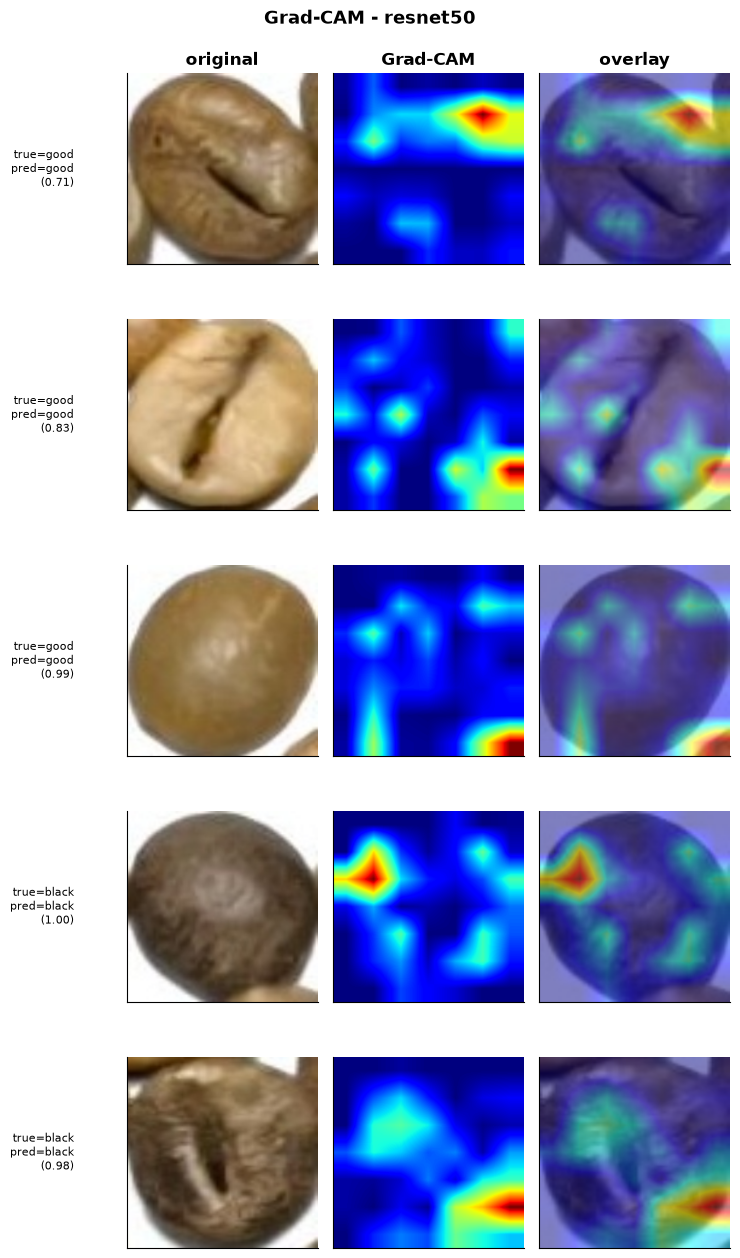

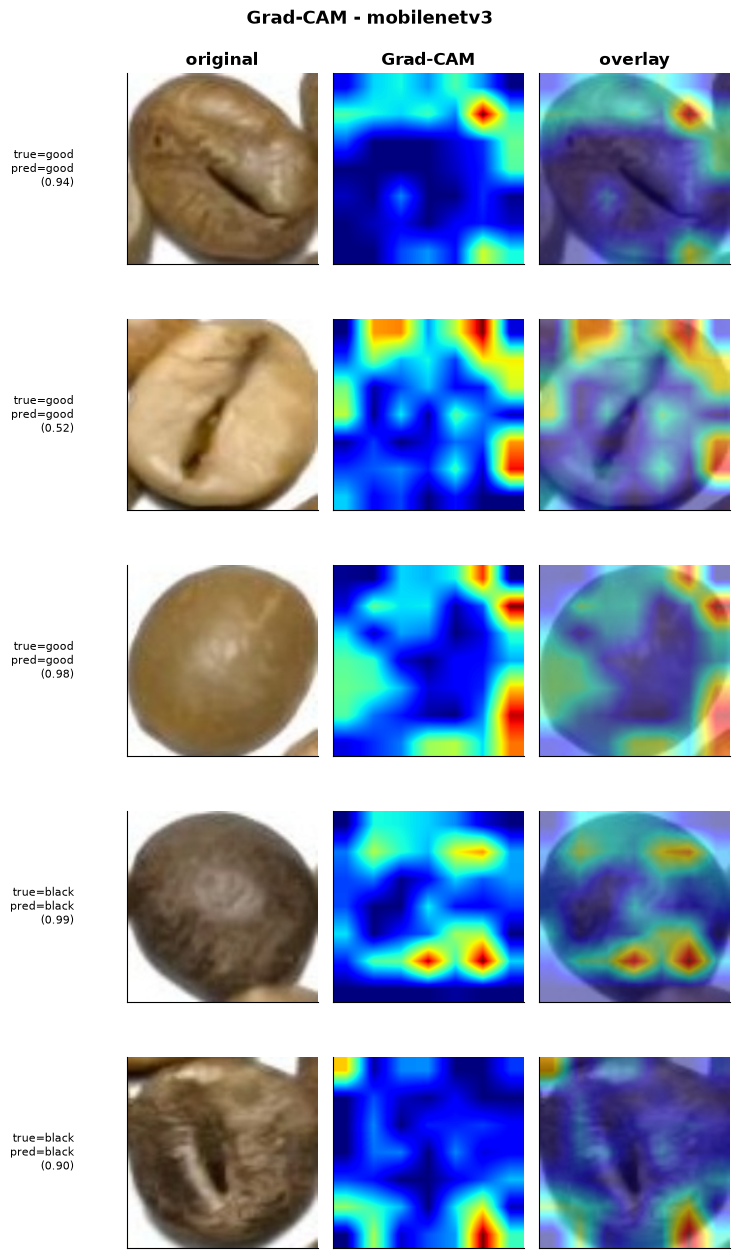

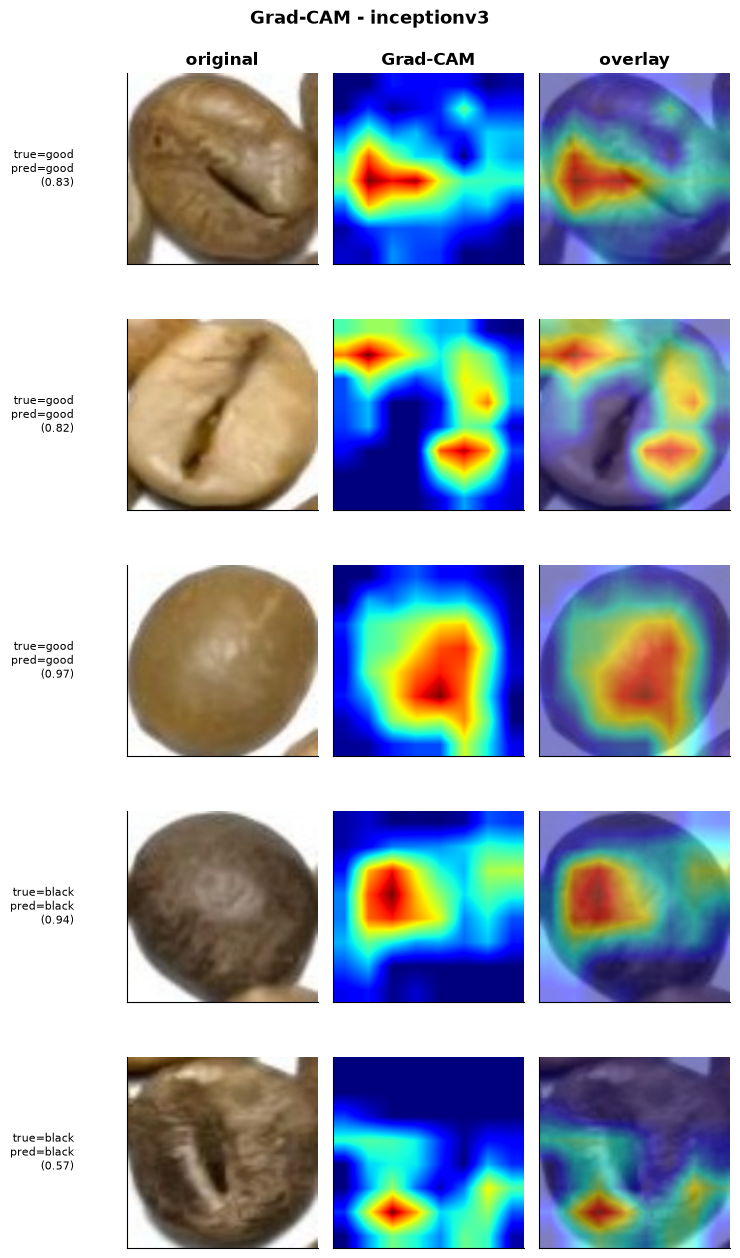

In [5]:
for name, model in models.items():
    analyzer = GradCAMAnalyzer(model, name, device=DEVICE)
    analyzer.visualize_batch(
        paths[:5],
        true_labels=labels[:5],
        class_names=CLASS_NAMES,
        output_path=FIGURES_DIR / f'{name}_gradcam.png',
    )
    plt.show()

## 4. Perbandingan antar-arsitektur pada sampel yang sama

Satu baris = satu biji, satu kolom = satu arsitektur. Inilah figur yang paling layak masuk paper: terlihat apakah ketiga model "sepakat" soal bagian biji yang menentukan.

Dengan `SAMPLE_MODE = 'benar'`, semua baris adalah prediksi benar — untuk `insect_damage`, perhatikan apakah heatmap menyorot **lubangnya**. Contoh yang salah ada di bagian 5.

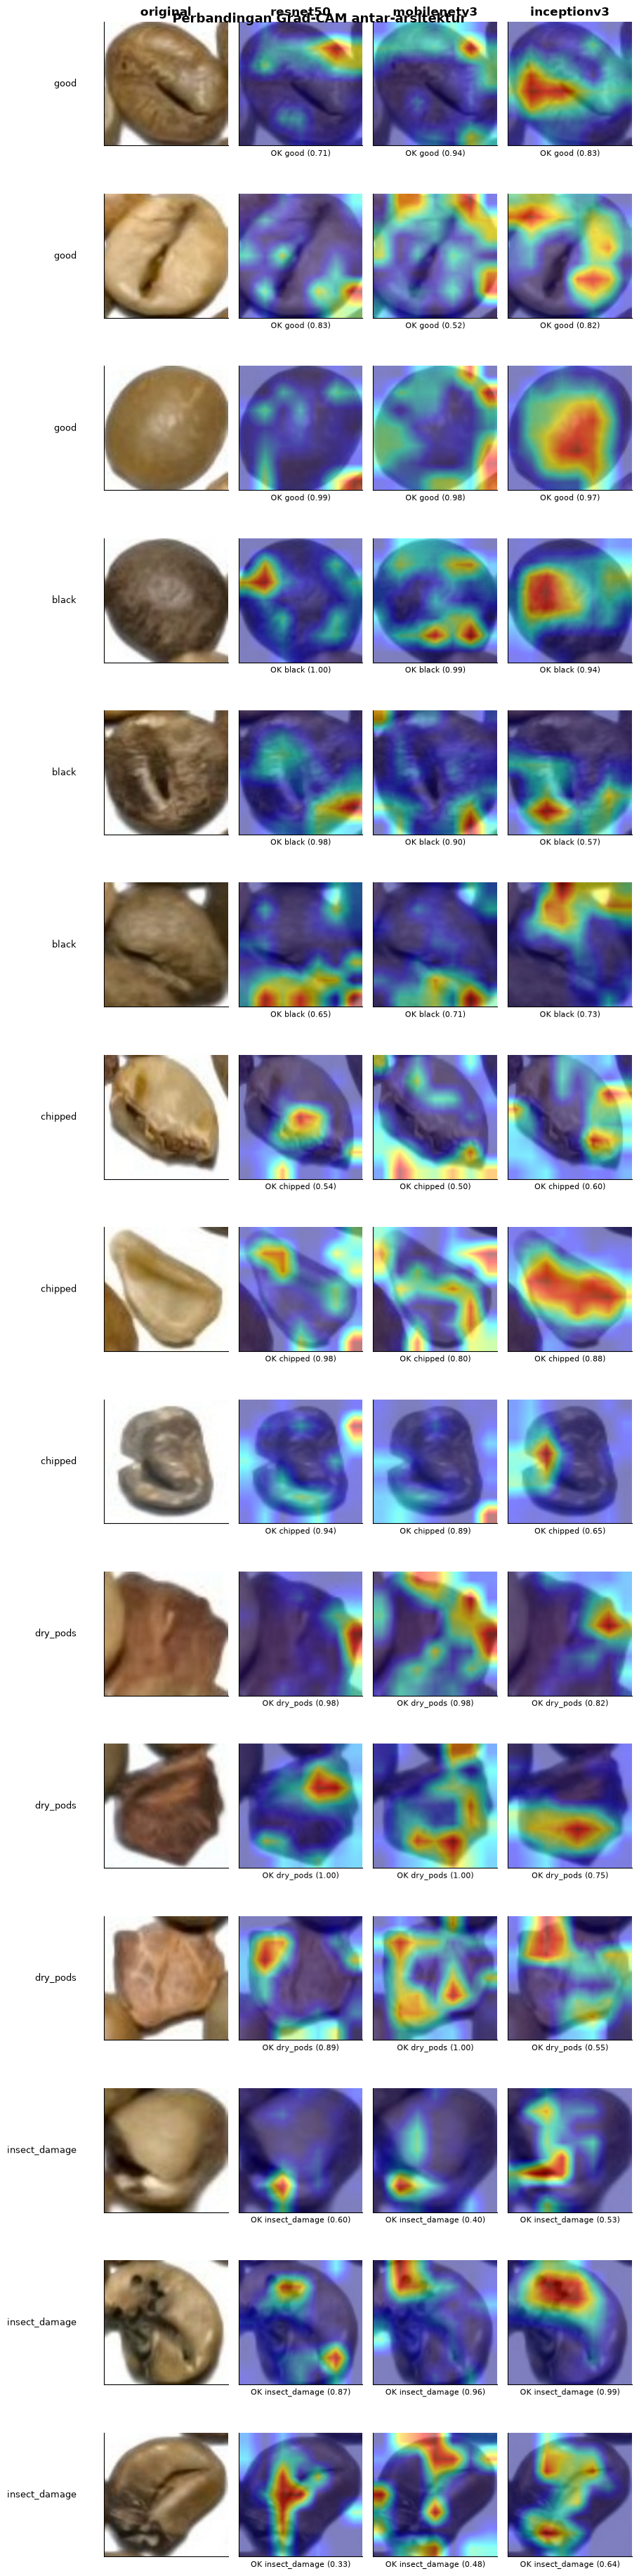

In [6]:
compare_architectures(
    models,
    paths,
    true_labels=labels,
    class_names=CLASS_NAMES,
    device=DEVICE,
    output_path=FIGURES_DIR / 'gradcam_comparison.png',
)
plt.show()

## 5. Grad-CAM pada prediksi yang salah

Bagian yang paling sering memberi penjelasan: apakah model melihat latar, bayangan, atau tepi crop alih-alih bijinya sendiri?

   true_label pred_label  confidence
      chipped   dry_pods    0.998369
         good      black    0.967567
insect_damage       good    0.929058
      chipped      black    0.925925
         good      black    0.914996


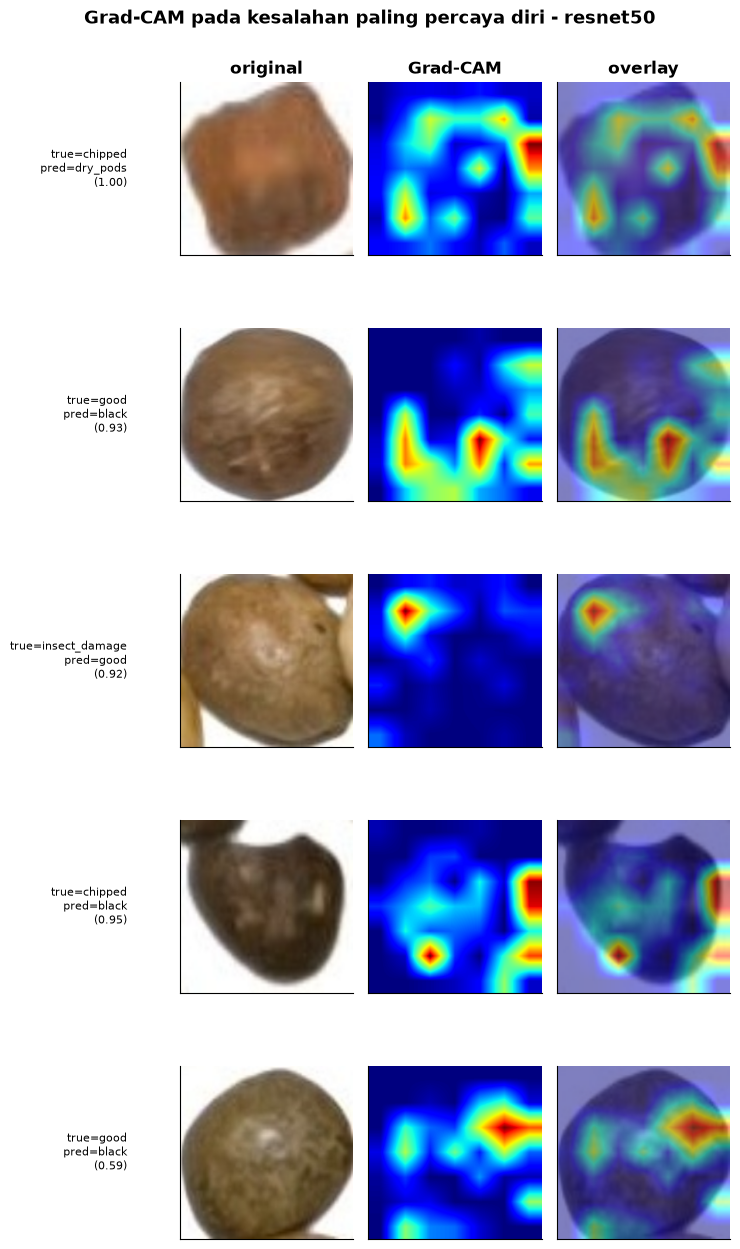

In [7]:
BEST_MODEL = next(iter(models))

from configs.base_config import ANALYSIS_DIR

pred_path = ANALYSIS_DIR / f'{BEST_MODEL}_test_predictions.csv'
if pred_path.exists():
    frame = load_predictions(pred_path)
    wrong = frame.loc[~frame['correct']].sort_values('confidence', ascending=False).head(5)

    if wrong.empty:
        print('Tidak ada prediksi salah pada model ini.')
    else:
        print(wrong[['true_label', 'pred_label', 'confidence']].to_string(index=False))
        analyzer = GradCAMAnalyzer(models[BEST_MODEL], BEST_MODEL, device=DEVICE)
        analyzer.visualize_batch(
            wrong['path'].tolist(),
            true_labels=wrong['y_true'].tolist(),
            class_names=CLASS_NAMES,
            output_path=FIGURES_DIR / f'{BEST_MODEL}_gradcam_errors.png',
            title=f'Grad-CAM pada kesalahan paling percaya diri - {BEST_MODEL}',
        )
        plt.show()
else:
    print(f'{pred_path.name} belum ada. Jalankan scripts.evaluate dulu.')